<h1><center>Практическое задание</h1></center>

1. Выбрать набор данных для обучения моеделй генерации изображений
2. Обучить собственные GaN и VAE и сравнить результаты генерации между собой

VAE обучалась ранее на датасете CIFAR10, следовательно выберем этот датасет

In [1]:
import torch
from torch import nn
from torchvision.transforms import transforms as T
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

In [2]:
import torch
print(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

cpu


In [27]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])


train_set = CIFAR10(root='D:/MIREA/DPO/Learning/Practic2_5/Cifar10', train=True,
                  download=False, transform=transform)
valid_set = CIFAR10(root='D:/MIREA/DPO/Learning/Practic2_5/Cifar10', train=False,
                  download=False, transform=transform)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cuda


In [81]:
class VAEEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # first verstion
            # nn.Conv2d(3, 32, kernel_size=3, padding=1),
            # nn.InstanceNorm2d(32),
            # nn.ReLU(),
            # nn.AvgPool2d(kernel_size=2),

            # nn.Conv2d(32, 64, kernel_size=3, padding=1),
            # nn.InstanceNorm2d(64),
            # nn.ReLU(),
            # nn.AvgPool2d(kernel_size=2),

            # nn.Conv2d(64, 128, kernel_size=3, padding=1),
            # nn.InstanceNorm2d(128),
            # nn.ReLU(),
            # nn.AvgPool2d(kernel_size=2),

            # nn.Conv2d(128, 256, kernel_size=4)

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.InstanceNorm2d(32),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.InstanceNorm2d(64),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.InstanceNorm2d(128),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.InstanceNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 512, kernel_size=4)
        )
    def forward(self, x):
        z = self.net(x)
        z_mu, z_log_sigma = z[:, :256], z[:, 256:]
        return z_mu, z_log_sigma

class VAEDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # first verstion
            # nn.ConvTranspose2d(128, 64, kernel_size=4),
            # nn.InstanceNorm2d(64),
            # nn.ReLU(),

            # nn.Conv2d(64, 32, kernel_size=5, padding=2),
            # nn.Upsample(scale_factor=2, mode='bilinear'),
            # nn.InstanceNorm2d(32),
            # nn.ReLU(),

            # nn.Conv2d(32, 16, kernel_size=5, padding=2),
            # nn.Upsample(scale_factor=2),
            # nn.InstanceNorm2d(16),
            # nn.ReLU(),

            # nn.Conv2d(16, 3, kernel_size=5, padding=2),
            # nn.Upsample(scale_factor=2, mode='bilinear')

            nn.ConvTranspose2d(256, 128, kernel_size=4),
            nn.InstanceNorm2d(128),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=5, padding=2),
            nn.InstanceNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.Upsample(scale_factor=2, mode='bilinear'),
            nn.InstanceNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 16, kernel_size=5, padding=2),
            nn.Upsample(scale_factor=2),
            nn.InstanceNorm2d(16),
            nn.ReLU(),

            nn.Conv2d(16, 3, kernel_size=5, padding=2),
            nn.Upsample(scale_factor=2, mode='bilinear')
        )
    def forward(self, z):
        x_mu = self.net(z)
        return x_mu

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = VAEEncoder()
        self.decoder = VAEDecoder()
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, x):
        return self.decoder(x)

    def new_parametrezation(self, mu, log_sigma, eps):
        return mu + torch.exp(.5 * log_sigma) * eps

    def forward(self, x):
        z_mu, z_log_sigma = self.encode(x)
        eps = torch.randn_like(z_mu)
        z = self.new_parametrezation(z_mu, z_log_sigma, eps)
        x_mu = self.decode(z)
        return z_mu, z_log_sigma, x_mu

class VAELoss(nn.Module):
    def forward(self, x, z_mu, z_log_sigma, x_mu, alpha = 1.0, beta = 1.0):
        z_sigma = torch.exp(z_log_sigma)
        rec_loss = ((x - x_mu).square().sum() / x.shape[0])
        rec_loss = .5 * rec_loss

        kl_loss = (-1 + -z_log_sigma + z_sigma + z_mu.square()).sum() / x.shape[0]
        kl_loss = .5 * kl_loss
        all_loss = alpha * rec_loss + beta * kl_loss
        return all_loss

In [82]:
vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=3e-4)
criterion = VAELoss()

train_loader = DataLoader(train_set, batch_size=128,
                          pin_memory=True, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128,
                          pin_memory=True, shuffle=False)

print(f'Number parameters of all VAE: {sum(p.numel() for p in vae.parameters())}.\n\
Number parameters of encoder: {sum(p.numel() for p in vae.encoder.parameters())}.\n\
Number parameters of decoder: {sum(p.numel() for p in vae.decoder.parameters())}')

Number parameters of all VAE: 3280611.
Number parameters of encoder: 2486080.
Number parameters of decoder: 794531


In [75]:
def VAE_learn(vae, optimizer, criterion, train_set, valid_set, train_loader, valid_loader, 
              device, num_epochs = 30, start_epoch=0, dop_name='', start_annealing_epoch=10,
              end_annealing_epoch=40, max_beta=1.0):
    train_loss = [.0 for _ in range(num_epochs)]
    valid_loss = [.0 for _ in range(num_epochs)] 
    for epoch_cycle in range(num_epochs):
        epoch = epoch_cycle + start_epoch
        if epoch < start_annealing_epoch:
            beta = 0.0
        elif epoch < end_annealing_epoch:
            progress = (epoch - start_annealing_epoch) / (end_annealing_epoch - start_annealing_epoch)
            beta = progress * max_beta
        else:
            beta = max_beta
        if (epoch % 10 == 0) or (epoch == num_epochs - 1):
            torch.save(vae.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_13/vae_weights_{dop_name}{epoch}.pt')
        vae.train()
        for images, _ in tqdm(train_loader, desc=f'Training {epoch:3d}/{num_epochs:3d}'):
            optimizer.zero_grad()
            images = images.to(device)
            out = vae(images)
            loss = criterion(images, *out, beta)
            loss.backward()
            optimizer.step()
            train_loss[epoch] += loss.item() * images.shape[0]

        vae.eval()
        with torch.inference_mode():
            for images, _ in tqdm(valid_loader, desc=f'validating: {epoch:3d}/{num_epochs:3d}'):
                images = images.to(device)
                out = vae(images)
                loss = criterion(images, *out, beta)
                valid_loss[epoch] += loss.item() * images.shape[0]

        train_loss[epoch] /= len(train_set)
        valid_loss[epoch] /= len(valid_set)

        print(f'{(epoch + 1):3d}/{num_epochs:3d}: train_loss: {train_loss[epoch]:2.3f} \
              valid_loss: {valid_loss[epoch]:2.3f}')
    return vae, optimizer, train_loss, valid_loss 

In [ ]:
vae, optimizer, train_loss_hist, valid_loss_hist = VAE_learn(vae, optimizer, criterion,
                                                             train_set, valid_set,
                                                             train_loader, valid_loader,
                                                             device, 60)

Training   0/ 60:   0%|          | 0/391 [00:00<?, ?it/s]

validating:   0/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

  1/ 60: train_loss: 230.234               valid_loss: 184.737


Training   1/ 60:   0%|          | 0/391 [00:00<?, ?it/s]

validating:   1/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

...

validating:  58/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

 59/ 60: train_loss: 128.720               valid_loss: 132.351


Training  59/ 60:   0%|          | 0/391 [00:00<?, ?it/s]

validating:  59/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

 60/ 60: train_loss: 128.663               valid_loss: 131.443


Text(0.5, 1.0, 'VAE criterions')

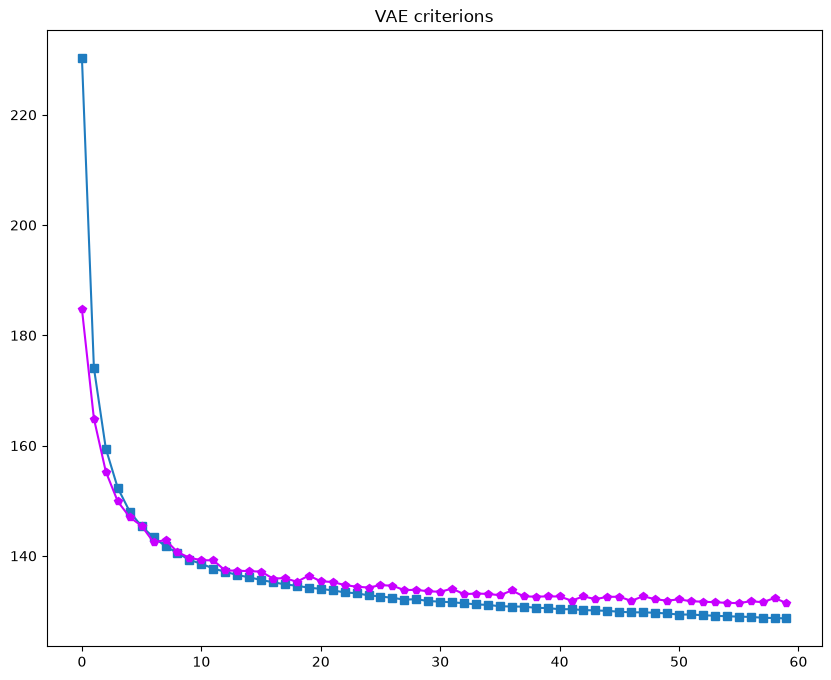

In [32]:
plt.figure(figsize=(10, 8))
plt.plot(range(len(train_loss_hist)), train_loss_hist, color='#1F7CC0', marker='s')
plt.plot(range(len(valid_loss_hist)), valid_loss_hist, color='#C800FF', marker='p')
plt.title("VAE criterions")

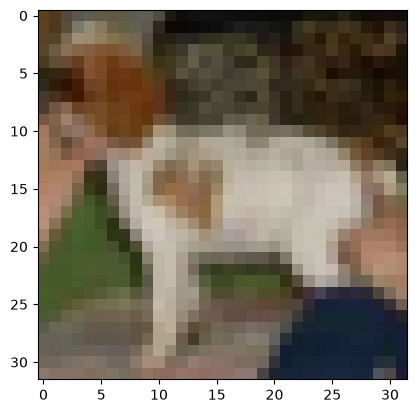

In [60]:
image = valid_set[12][0].permute(1, 2, 0)
plt.imshow((image + 1) / 2)
image = valid_set[12][0].unsqueeze(0)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.022968233..0.86114687].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0011743307..1.1575785].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.08538389..1.1816195].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.10078144..0.91377074].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.24822292..1.0484366].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.032642722..0.8713411].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range 

tensor([[[0.4268, 0.3738, 0.2863],
         [0.4272, 0.3708, 0.2817],
         [0.4279, 0.3648, 0.2725],
         ...,
         [0.1788, 0.1462, 0.1000],
         [0.1631, 0.1345, 0.0904],
         [0.1553, 0.1286, 0.0857]],

        [[0.4268, 0.3727, 0.2809],
         [0.4272, 0.3697, 0.2772],
         [0.4279, 0.3638, 0.2697],
         ...,
         [0.1727, 0.1372, 0.0940],
         [0.1580, 0.1266, 0.0837],
         [0.1507, 0.1212, 0.0786]],

        [[0.4268, 0.3705, 0.2703],
         [0.4272, 0.3676, 0.2683],
         [0.4279, 0.3620, 0.2643],
         ...,
         [0.1604, 0.1193, 0.0819],
         [0.1478, 0.1107, 0.0704],
         [0.1416, 0.1064, 0.0646]],

        ...,

        [[0.4113, 0.3851, 0.3345],
         [0.4091, 0.3832, 0.3332],
         [0.4046, 0.3793, 0.3307],
         ...,
         [0.1636, 0.1323, 0.1256],
         [0.1730, 0.1409, 0.1388],
         [0.1776, 0.1451, 0.1454]],

        [[0.3957, 0.3770, 0.3221],
         [0.3918, 0.3713, 0.3185],
         [0.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0586811..1.028749].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1366204..1.0432334].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.07470423..1.0404193].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.11657593..1.1412469].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.051244497..1.0199497].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0005298257..0.6948918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.05119

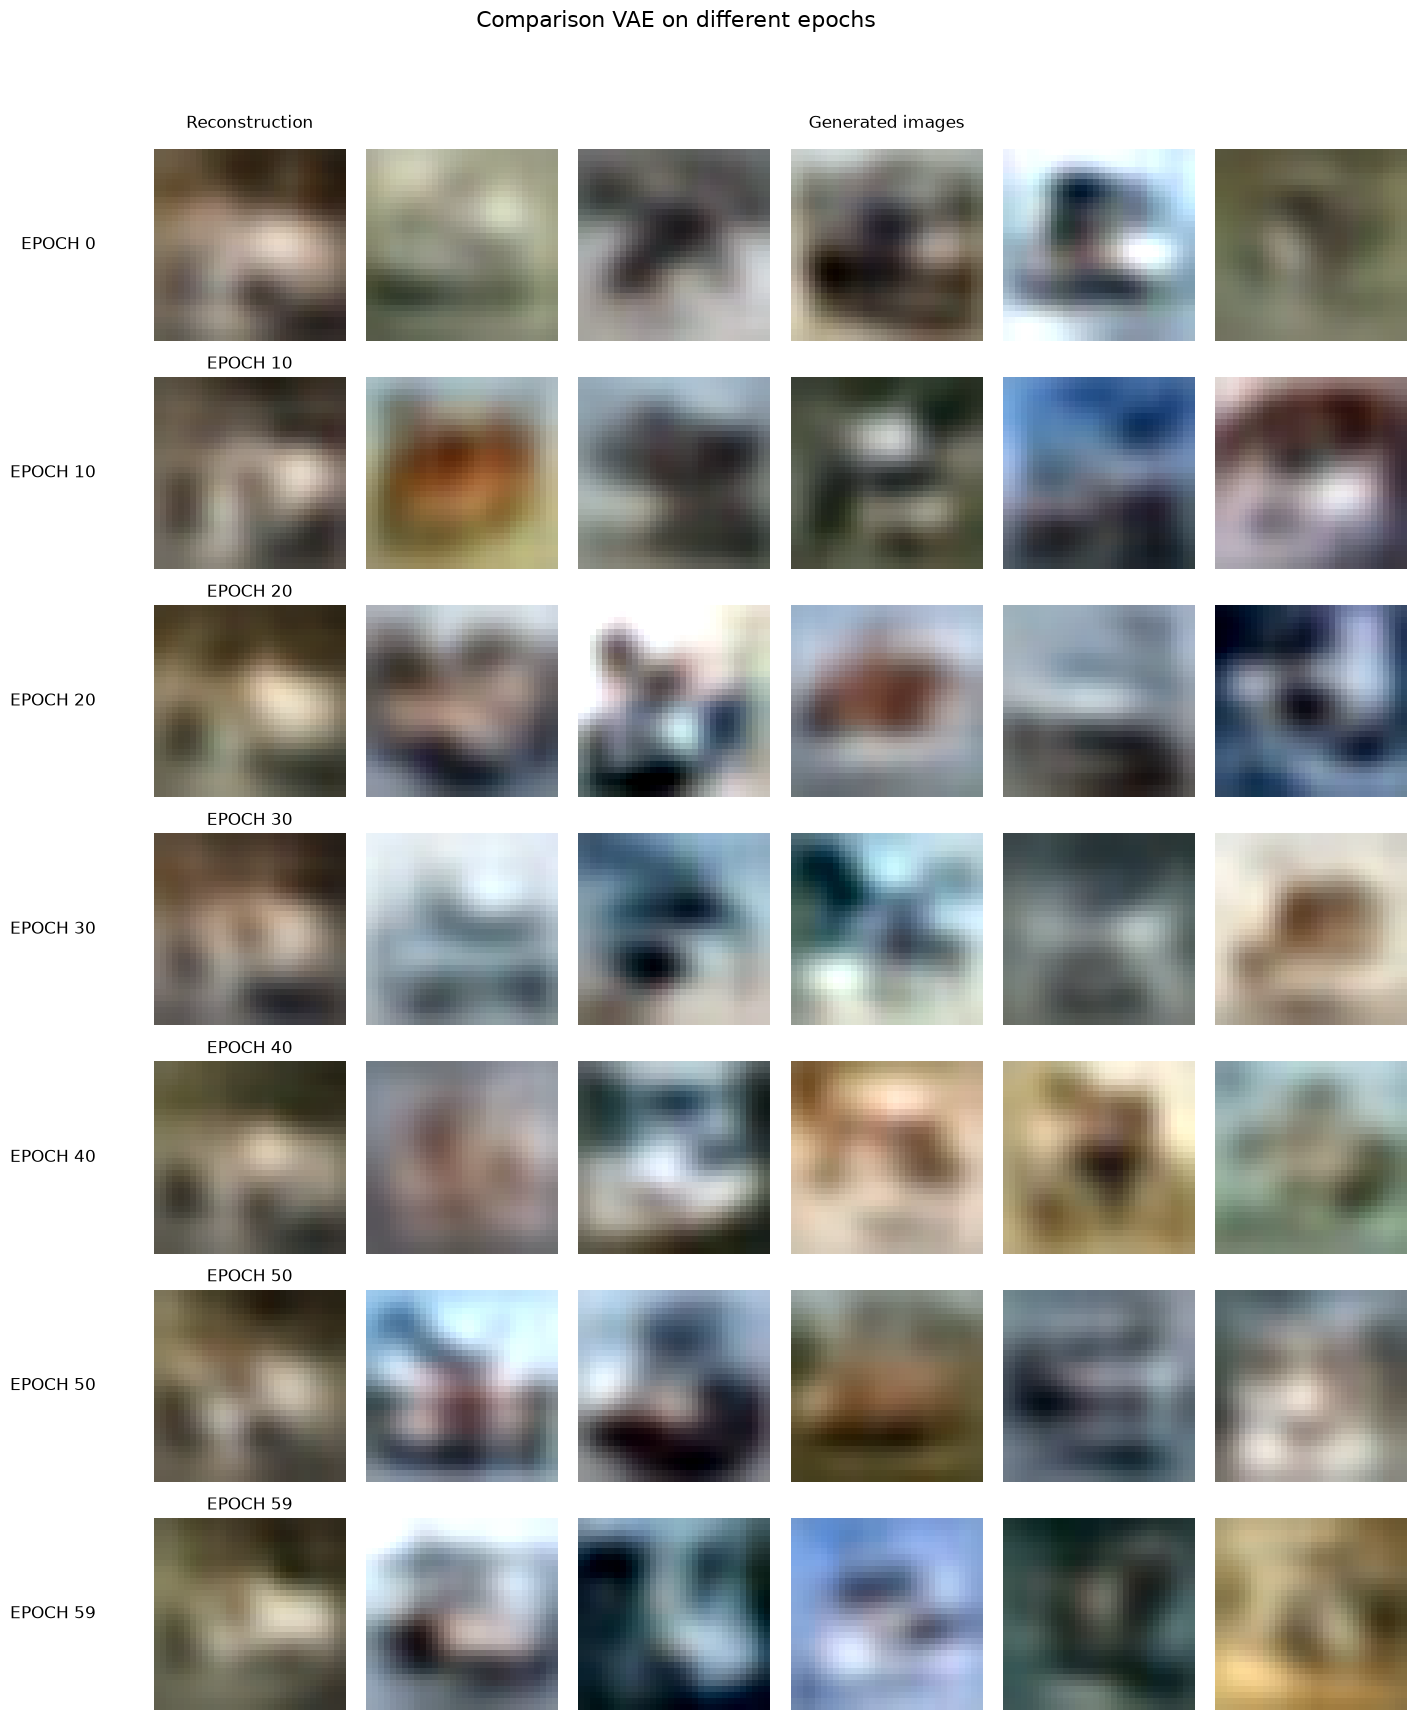

In [72]:
import glob


files = glob.glob('D:/MIREA/DPO/Learning/Practic2_13/vae_weights_home_*.pt')
number_to_represent = len(files)
epochs = [int(f[51:-3]) for f in files]
len_epochs = len(epochs)
fig, ax = plt.subplots(len_epochs, 6, figsize=(15, 2.5 * len_epochs))
plt.suptitle("Comparison VAE on different epochs", fontsize=16)

for row, epoch in enumerate(epochs):
    vae_repr = VAE()
    vae_repr_weights = torch.load(f'D:/MIREA/DPO/Learning/Practic2_13/vae_weights_home_{epoch}.pt')
    vae_repr.load_state_dict(vae_repr_weights)
    vae_repr = vae_repr.to('cpu')
    with torch.inference_mode():
        _, _, rec_image = vae_repr(image)
    
    img_to_show = ((rec_image[0] + 1) / 2).detach().cpu().permute(1, 2, 0)
    if (epoch == 0):
        print(img_to_show)
    ax[row][0].imshow(img_to_show)
    z_mu, z_log_sigma = vae_repr.encode(image)
    ax[row][0].set_title(f'EPOCH {epoch}')
    ax[row][0].axis('off')

    if row == 0:
        ax[row][0].set_title("Reconstruction", fontsize=12, pad=15)
    
    ax[row][0].text(-0.3, 0.5, f'EPOCH {epoch}', fontsize=12,
                    va='center', ha='right', transform=ax[row][0].transAxes)

    for col in range(5):
        with torch.inference_mode():
            z = torch.randn_like(z_mu)
            rec_image = vae_repr.decode(z)
            img_to_show = ((rec_image[0] + 1) / 2).detach().cpu().permute(1, 2, 0)
            ax[row][col + 1].imshow(img_to_show)
            ax[row][col + 1].axis('off')
            if (row == 0) and (col == 2):
                ax[row][col + 1].set_title("Generated images", fontsize=12, pad=15)

plt.tight_layout(rect=[0.05, 0, 1, 0.95])
plt.show()

In [ ]:
vae, optimizer, train_loss_hist_from60, valid_loss_hist_from60 = VAE_learn(vae, optimizer, criterion,
                                                                            train_set, valid_set,
                                                                            train_loader, valid_loader,
                                                                            device, 60, 60)

Training   0/ 60:   0%|          | 0/391 [00:00<?, ?it/s]

validating:   0/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

  1/ 60: train_loss: 128.494               valid_loss: 131.880


Training   1/ 60:   0%|          | 0/391 [00:00<?, ?it/s]

validating:   1/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

...

validating:  58/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

 59/ 60: train_loss: 125.674               valid_loss: 129.592


Training  59/ 60:   0%|          | 0/391 [00:00<?, ?it/s]

validating:  59/ 60:   0%|          | 0/79 [00:00<?, ?it/s]

 60/ 60: train_loss: 125.623               valid_loss: 130.099


In [83]:
vae, optimizer, train_loss_hist, valid_loss_hist = VAE_learn(vae, optimizer, criterion,
                                                             train_set, valid_set,
                                                             train_loader, valid_loader,
                                                             device, num_epochs=80, dop_name='version2_')

Training   0/ 80:   0%|          | 0/391 [00:00<?, ?it/s]

validating:   0/ 80:   0%|          | 0/79 [00:00<?, ?it/s]

  1/ 80: train_loss: 1.013               valid_loss: 0.096


Training   1/ 80:   0%|          | 0/391 [00:00<?, ?it/s]

validating:   1/ 80:   0%|          | 0/79 [00:00<?, ?it/s]

...

validating:  78/ 80:   0%|          | 0/79 [00:00<?, ?it/s]

 79/ 80: train_loss: 131.313               valid_loss: 134.168


Training  79/ 80:   0%|          | 0/391 [00:00<?, ?it/s]

validating:  79/ 80:   0%|          | 0/79 [00:00<?, ?it/s]

 80/ 80: train_loss: 131.329               valid_loss: 134.567


In [84]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1),
            nn.InstanceNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.InstanceNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.InstanceNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
            nn.InstanceNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0),
            nn.Flatten(),
            nn.Sigmoid()
        )
    
    def forward(self, X):
        return self.model(X)
    
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.ConvTranspose2d(100, 512, kernel_size=4, stride=1, padding=0),
            nn.InstanceNorm2d(512),
            nn.LeakyReLU(0.2, True),
            
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.InstanceNorm2d(256),
            nn.LeakyReLU(0.2, True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.InstanceNorm2d(128),
            nn.LeakyReLU(0.2, True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.InstanceNorm2d(64),
            nn.LeakyReLU(0.2, True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(64, 3, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, X):
        return self.model(X)
    
disc = Discriminator()
gen = Generator()

print('Num params of discriminator: %d.' % sum(p.numel() for p in disc.parameters()))
print('Num params of generator: %d.' % sum(p.numel() for p in gen.parameters()))

EPOCHS = 60
lr = .0002
betas = (0.5, 0.999)
criterion = nn.BCELoss()
optim_disc = torch.optim.Adam(disc.parameters(), lr=lr, betas=betas)
optim_gen = torch.optim.Adam(gen.parameters(), lr=lr, betas=betas)
disc.to(device)
gen.to(device)

from tqdm.notebook import tqdm

for epoch in tqdm(range(EPOCHS)):
    loss_gen_stat = 0.0
    loss_disc_stat = 0.0
    if (epoch % 10 == 0) or (epoch == EPOCHS - 1):
        torch.save(gen.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_13/generator_conv_weights_{epoch}.pt')
        torch.save(disc.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_13/discriminator_conv_weights_{epoch}.pt')
    for n, (real_sample, real_label) in enumerate(tqdm(train_loader)):
        current_batch_size = real_sample.size(0)
        real_sample, real_label = real_sample.to(device), real_label.to(device)
        real_label = torch.full((current_batch_size, 1), 0.9).to(device)
        noise_samples = torch.randn((current_batch_size, 100, 1, 1)).to(device)
        generated_samples = gen(noise_samples)
        generated_labels = torch.zeros((current_batch_size, 1)).to(device)
        all_samples = torch.cat((real_sample, generated_samples.detach())).to(device)
        all_labels = torch.cat((real_label, generated_labels)).to(device)

        disc.zero_grad()
        output_disc = disc(all_samples)
        loss_disc = criterion(output_disc, all_labels)
        loss_disc_stat += loss_disc.item()
        loss_disc.backward()
        optim_disc.step()

        gen.zero_grad()
        generated_samples = gen(noise_samples)
        output_disc_gen = disc(generated_samples)
        loss_disc_gen = criterion(output_disc_gen, real_label)
        loss_gen_stat += loss_disc_gen.item()
        loss_disc_gen.backward()
        optim_gen.step()

    print(f'Loss G: {loss_gen_stat / len(train_loader)}, \
          Loss D {loss_disc_stat / len(train_loader)}')

Num params of discriminator: 1847233.
Num params of generator: 2370179.


  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

Loss G: 3.4839190217235205,           Loss D 0.40921994228192304


  0%|          | 0/391 [00:00<?, ?it/s]

...

Loss G: 4.982031410002647,           Loss D 0.22059441801837032


  0%|          | 0/391 [00:00<?, ?it/s]

Loss G: 5.176578640632922,           Loss D 0.2172013701837691


  0%|          | 0/391 [00:00<?, ?it/s]

Loss G: 5.032091566973635,           Loss D 0.21776193631884386
